In [2]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv

In [3]:
load_dotenv()

llm = ChatGoogleGenerativeAI(model = "gemini-2.5-flash")

In [4]:
class JokeState(TypedDict):
    topic : str
    joke : str
    explanation : str

In [5]:
def generate_joke(state : JokeState):
    prompt = f"generate a joke on the topic {state["topic"]}"
    response = llm.invoke(prompt)

    return {"joke" : response.content}

In [6]:
def explain_joke(state : JokeState):
    prompt = f"write an explanation for the joke {state["joke"]}"
    response = llm.invoke(prompt)

    return {"explanation" : response.content}

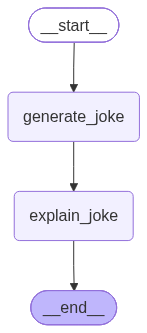

In [7]:
graph = StateGraph(JokeState)

graph.add_node("generate_joke", generate_joke)
graph.add_node("explain_joke", explain_joke)

graph.add_edge(START, "generate_joke")
graph.add_edge("generate_joke", "explain_joke")
graph.add_edge("explain_joke", END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)
workflow

In [8]:
config = {"configurable" : {"thread_id" : "1"}}
response = workflow.invoke({'topic' : 'pizza'}, config=config)
response

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


{'topic': 'pizza',
 'joke': 'Why did the pizza get a job?\n\nBecause it needed to earn some **dough**!',
 'explanation': 'This joke is a classic **pun**! It plays on the double meaning of the word "dough."\n\nHere\'s the breakdown:\n\n1.  **"Dough" as in pizza ingredient:** When you think of pizza, "dough" is the fundamental base – the mixture of flour, water, yeast, etc., that forms the crust. So, a pizza literally *is* dough, or at least made from it.\n\n2.  **"Dough" as in money (slang):** In informal English, "dough" is a common slang term for money. For example, "I need to earn some dough to pay my bills."\n\nThe joke works by setting up a scenario where a pizza (an inanimate object) is given a human characteristic (getting a job). The punchline then uses the word "dough" to connect the pizza\'s physical nature (it\'s made of dough) with the human reason for getting a job (to earn money, also called dough).\n\nIt\'s funny because it\'s an unexpected twist that uses a word with a p

In [9]:
workflow.get_state(config)

StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza get a job?\n\nBecause it needed to earn some **dough**!', 'explanation': 'This joke is a classic **pun**! It plays on the double meaning of the word "dough."\n\nHere\'s the breakdown:\n\n1.  **"Dough" as in pizza ingredient:** When you think of pizza, "dough" is the fundamental base – the mixture of flour, water, yeast, etc., that forms the crust. So, a pizza literally *is* dough, or at least made from it.\n\n2.  **"Dough" as in money (slang):** In informal English, "dough" is a common slang term for money. For example, "I need to earn some dough to pay my bills."\n\nThe joke works by setting up a scenario where a pizza (an inanimate object) is given a human characteristic (getting a job). The punchline then uses the word "dough" to connect the pizza\'s physical nature (it\'s made of dough) with the human reason for getting a job (to earn money, also called dough).\n\nIt\'s funny because it\'s an unexpected twist that u

In [10]:
list(workflow.get_state_history(config))

[StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza get a job?\n\nBecause it needed to earn some **dough**!', 'explanation': 'This joke is a classic **pun**! It plays on the double meaning of the word "dough."\n\nHere\'s the breakdown:\n\n1.  **"Dough" as in pizza ingredient:** When you think of pizza, "dough" is the fundamental base – the mixture of flour, water, yeast, etc., that forms the crust. So, a pizza literally *is* dough, or at least made from it.\n\n2.  **"Dough" as in money (slang):** In informal English, "dough" is a common slang term for money. For example, "I need to earn some dough to pay my bills."\n\nThe joke works by setting up a scenario where a pizza (an inanimate object) is given a human characteristic (getting a job). The punchline then uses the word "dough" to connect the pizza\'s physical nature (it\'s made of dough) with the human reason for getting a job (to earn money, also called dough).\n\nIt\'s funny because it\'s an unexpected twist that 

In [12]:
# select the checkpoint id dynamically (i selected the generate joke node)

final_state = workflow.invoke(None, config= {"configurable" : {"thread_id" : "1", "checkpoint_id" : "1f1bb4bd-6354-69bd-8000-10ba9ef1139b"}} )
final_state

{'topic': 'pizza',
 'joke': "Why did the pizza chef get fired?\n\nBecause he couldn't make the **dough**!",
 'explanation': 'This is a classic pun joke that plays on the double meaning of the word "dough"!\n\nHere\'s the breakdown:\n\n1.  **Meaning 1 (Literal - Pizza Related):** When you hear "pizza chef" and "dough," your first thought is the literal dough – the mixture of flour, water, yeast, etc., that forms the base of the pizza crust. If a pizza chef genuinely couldn\'t make *that* kind of dough, they\'d certainly be fired because it\'s fundamental to their job.\n\n2.  **Meaning 2 (Slang - Money):** "Dough" is also a common slang term for **money**. The phrase "to make dough" means to earn money.\n\n**The Punchline:**\n\nThe joke sets you up to think about the literal pizza dough, but the punchline uses the *other* meaning of "dough" (money). People are often fired from jobs if they aren\'t performing well enough to "make dough" (money) for the business, or if they aren\'t seen as

In [13]:
list(workflow.get_state_history(config))

[StateSnapshot(values={'topic': 'pizza', 'joke': "Why did the pizza chef get fired?\n\nBecause he couldn't make the **dough**!", 'explanation': 'This is a classic pun joke that plays on the double meaning of the word "dough"!\n\nHere\'s the breakdown:\n\n1.  **Meaning 1 (Literal - Pizza Related):** When you hear "pizza chef" and "dough," your first thought is the literal dough – the mixture of flour, water, yeast, etc., that forms the base of the pizza crust. If a pizza chef genuinely couldn\'t make *that* kind of dough, they\'d certainly be fired because it\'s fundamental to their job.\n\n2.  **Meaning 2 (Slang - Money):** "Dough" is also a common slang term for **money**. The phrase "to make dough" means to earn money.\n\n**The Punchline:**\n\nThe joke sets you up to think about the literal pizza dough, but the punchline uses the *other* meaning of "dough" (money). People are often fired from jobs if they aren\'t performing well enough to "make dough" (money) for the business, or if 

In [15]:
workflow.update_state({"configurable" : {"thread_id" : "1", "checkpoint_id" : "1f1bb4c0-149d-6991-8001-8cadbe96ae2c", "checkpoint_ns" : ""}}, {"topic" : "samosa"})

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1bb4c4-86d0-614a-8002-c88546a5a4c1'}}

In [16]:
list(workflow.get_state_history(config))

[StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1bb4c4-86d0-614a-8002-c88546a5a4c1'}}, metadata={'source': 'update', 'step': 2, 'parents': {}}, created_at='2026-09-28T14:52:53.220794+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1bb4c0-149d-6991-8001-8cadbe96ae2c'}}, tasks=(PregelTask(id='7f2840e3-d8d1-91a3-3dd9-fe1fa8ca70a5', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'pizza', 'joke': "Why did the pizza chef get fired?\n\nBecause he couldn't make the **dough**!", 'explanation': 'This is a classic pun joke that plays on the double meaning of the word "dough"!\n\nHere\'s the breakdown:\n\n1.  **Meaning 1 (Literal - Pizza Related):** When you hear "pizza chef" and "dough," your first thought is the literal dough 

In [17]:
workflow.invoke(None, config= {"configurable" : {"thread_id" : "1", "checkpoint_id" : "1f1bb4c4-86d0-614a-8002-c88546a5a4c1"}} )

{'topic': 'samosa',
 'joke': 'Why did the samosa get good grades?\n\nBecause it always knew all the **angles**!',
 'explanation': 'This joke is a pun that plays on the double meaning of the word "angles":\n\n1.  **Literal Meaning (Samosa):** A samosa is a triangular, fried pastry. Because of its distinct shape, it *literally* has angles – corners and edges that form geometric angles.\n\n2.  **Figurative Meaning (Grades/Success):** The phrase "knowing all the angles" is an idiom. It means understanding all aspects of a situation, knowing all the ins and outs, being shrewd, strategic, or having a comprehensive grasp of how things work. A student who "knows all the angles" would be someone who understands the material thoroughly, knows how to approach different types of problems, and perhaps even how to study effectively or what the teacher expects, leading to good grades.\n\nThe humor comes from the joke playfully attributing the human quality of strategic thinking (knowing all the angle

In [18]:
list(workflow.get_state_history(config))

[StateSnapshot(values={'topic': 'samosa', 'joke': 'Why did the samosa get good grades?\n\nBecause it always knew all the **angles**!', 'explanation': 'This joke is a pun that plays on the double meaning of the word "angles":\n\n1.  **Literal Meaning (Samosa):** A samosa is a triangular, fried pastry. Because of its distinct shape, it *literally* has angles – corners and edges that form geometric angles.\n\n2.  **Figurative Meaning (Grades/Success):** The phrase "knowing all the angles" is an idiom. It means understanding all aspects of a situation, knowing all the ins and outs, being shrewd, strategic, or having a comprehensive grasp of how things work. A student who "knows all the angles" would be someone who understands the material thoroughly, knows how to approach different types of problems, and perhaps even how to study effectively or what the teacher expects, leading to good grades.\n\nThe humor comes from the joke playfully attributing the human quality of strategic thinking (k